# **Predicción de desechos de comida en locales comerciales**
# **Grupo 55**

### **Importamos librerias**

In [1]:
# Manipulación y análisis de datos

import pandas as pd
import numpy as np

# Visualización de datos y resultados

import matplotlib.pyplot as plt
import seaborn as sns

# Imputación de nulos, escalado y codificación

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Regresión Lineal, Regresión Logística y Random Forest

from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestRegressor

# Regresión y clasificación

from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score, accuracy_score, f1_score, roc_auc_score)

# Visualización de métricas de clasificación

from sklearn.metrics import ( ConfusionMatrixDisplay,RocCurveDisplay)

### **Importamos el dataset**

In [2]:
raw_df = pd.read_csv('food_waste_dataset.csv') 

### **Análisis exploratorio de datos**

In [3]:
print("Dimensiones del Dataset:", raw_df.shape)

Dimensiones del Dataset: (8000, 16)


In [4]:
print("Primeras filas del Dataset:")
display(raw_df.head())

Primeras filas del Dataset:


,Inventory_ID,Date,Business_Type,Food_Category,Purchase_Quantity,Units_Sold,Remaining_Stock,Shelf_Life_Days,Storage_Temperature,Daily_Demand,Promotion,Weather,Waste_Quantity,Waste_Reason,Donation_Made,Waste_Level
0,INV000001,2025-01-01,Restaurant,Bakery,77,77,0,4.0,20.4,77.0,No,Sunny,0,No Waste,No,Low
1,INV000002,2025-01-01,Cafeteria,Bakery,75,53,22,3.0,22.8,53.0,No,Cloudy,6,Low Demand,No,Medium
2,INV000003,2025-01-01,Supermarket,Fruits,176,159,17,6.0,12.4,159.0,No,Sunny,4,Expired,No,Medium
3,INV000004,2025-01-01,Cafeteria,Dairy,58,58,0,7.0,3.5,83.0,Yes,Cloudy,0,No Waste,No,Low
4,INV000005,2025-01-01,Restaurant,Fruits,85,85,0,3.0,3.3,87.0,No,Hot,0,No Waste,No,Low


In [5]:
print("Columnas del Dataset:")
display(raw_df.columns)

Columnas del Dataset:


Index(['Inventory_ID', 'Date', 'Business_Type', 'Food_Category',
       'Purchase_Quantity', 'Units_Sold', 'Remaining_Stock', 'Shelf_Life_Days',
       'Storage_Temperature', 'Daily_Demand', 'Promotion', 'Weather',
       'Waste_Quantity', 'Waste_Reason', 'Donation_Made', 'Waste_Level'],
      dtype='object')

In [6]:
print("Información General del Dataset:")
display(raw_df.info())

Información General del Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Inventory_ID         8000 non-null   object 
 1   Date                 8000 non-null   object 
 2   Business_Type        8000 non-null   object 
 3   Food_Category        8000 non-null   object 
 4   Purchase_Quantity    8000 non-null   int64  
 5   Units_Sold           8000 non-null   int64  
 6   Remaining_Stock      8000 non-null   int64  
 7   Shelf_Life_Days      7765 non-null   float64
 8   Storage_Temperature  7814 non-null   float64
 9   Daily_Demand         7790 non-null   float64
 10  Promotion            8000 non-null   object 
 11  Weather              7797 non-null   object 
 12  Waste_Quantity       8000 non-null   int64  
 13  Waste_Reason         8000 non-null   object 
 14  Donation_Made        7767 non-null   object 
 15  Waste

None

In [7]:
print("Información Estadística del Dataset:")
display(raw_df.describe())

Información Estadística del Dataset:


,Purchase_Quantity,Units_Sold,Remaining_Stock,Shelf_Life_Days,Storage_Temperature,Daily_Demand,Waste_Quantity
count,8000.000000,8000.000000,8000.000000,7765.000000,7814.000000,7790.000000,8000.000000
mean,118.288750,96.959625,21.329125,4.364585,10.450064,105.099358,5.772375
std,58.685297,39.282291,41.663906,2.598122,8.431281,45.162475,16.450741
min,35.000000,26.000000,0.000000,1.000000,-4.400000,26.000000,0.000000
25%,80.000000,67.000000,0.000000,2.000000,3.700000,71.000000,0.000000
50%,104.000000,87.000000,9.000000,4.000000,7.500000,94.000000,1.000000
75%,148.000000,121.000000,30.000000,6.000000,18.100000,132.000000,7.000000
max,968.000000,284.000000,858.000000,14.000000,36.600000,316.000000,447.000000


In [8]:
print("Valores nulos por columna:")
display(raw_df.isnull().sum())

Valores nulos por columna:


Inventory_ID             0
Date                     0
Business_Type            0
Food_Category            0
Purchase_Quantity        0
Units_Sold               0
Remaining_Stock          0
Shelf_Life_Days        235
Storage_Temperature    186
Daily_Demand           210
Promotion                0
Weather                203
Waste_Quantity           0
Waste_Reason             0
Donation_Made          233
Waste_Level              0
dtype: int64

In [9]:
print("Valores duplicados :")
display(raw_df.duplicated().sum())

Valores duplicados :


np.int64(0)

### **Eliminacion de variables que no aportan a los modelos:**

In [10]:
print("Se eliminó la variable Inventory_ID por ser un identificador único sin valor predictivo. Es la única columna descartada inicialmente por no aportar información relevante al análisis.")

raw_df.drop(columns=['Inventory_ID'], inplace=True)

Se eliminó la variable Inventory_ID por ser un identificador único sin valor predictivo. Es la única columna descartada inicialmente por no aportar información relevante al análisis.


In [11]:
print ("Se eliminó la variable Waste_Level por tratarse de una clasificación basada en la cantidad de desperdicio.\n Al estar derivada de la variable objetivo, podría generar fuga de información durante el entrenamiento del modelo.")

raw_df.drop(columns=['Waste_Level'], inplace=True)

Se eliminó la variable Waste_Level por tratarse de una clasificación basada en la cantidad de desperdicio.
 Al estar derivada de la variable objetivo, podría generar fuga de información durante el entrenamiento del modelo.


In [12]:
print ("Se eliminó la variable Donation_Made por estar directamente relacionada con el excedente de alimentos, lo que podría generar fuga de información durante el entrenamiento del modelo.")

raw_df.drop(columns=['Donation_Made'], inplace=True)

Se eliminó la variable Donation_Made por estar directamente relacionada con el excedente de alimentos, lo que podría generar fuga de información durante el entrenamiento del modelo.


In [13]:
print ("Se eliminó la variable Waste_Reason por ser una variable categórica que describe la razón del desperdicio de alimentos, lo que podría generar fuga de información durante el entrenamiento del modelo.")

raw_df.drop(columns=['Waste_Reason'], inplace=True)

Se eliminó la variable Waste_Reason por ser una variable categórica que describe la razón del desperdicio de alimentos, lo que podría generar fuga de información durante el entrenamiento del modelo.


In [14]:
print("Se eliminó la variable Remaining_Stock por presentar una relación muy alta con la variable objetivo.")

raw_df.drop(columns=['Remaining_Stock'], inplace=True)

Se eliminó la variable Remaining_Stock por presentar una relación muy alta con la variable objetivo.


In [15]:
print("Se eliminó la variable Units_Sold por estar directamente relacionada con las ventas finales del período analizado.")

raw_df.drop(columns=['Units_Sold'], inplace=True)

Se eliminó la variable Units_Sold por estar directamente relacionada con las ventas finales del período analizado.


In [16]:
print("La columna Date se transforma a tipo datetime para utilizarla posteriormente en la división temporal del conjunto de datos. Por lo tanto, no será incluida en el proceso de One-Hot Encoding.")

raw_df['Date'] = pd.to_datetime(raw_df['Date'])

La columna Date se transforma a tipo datetime para utilizarla posteriormente en la división temporal del conjunto de datos. Por lo tanto, no será incluida en el proceso de One-Hot Encoding.


### **Análisis Gráfico de las Variables**

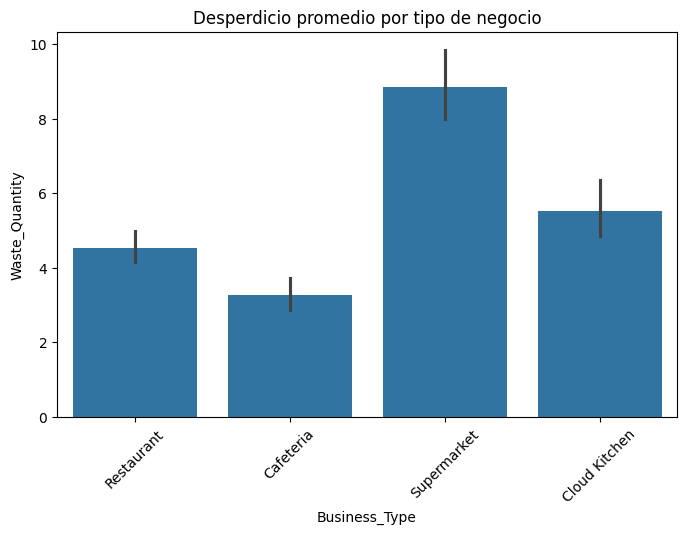

Los supermercados registran el mayor desperdicio promedio de alimentos, mientras que las cafeterías presentan el menor. Esto indica que el tipo de negocio puede influir en la cantidad de desperdicio generada.


In [17]:
# comparamos el desperdicio promedio por tipo de negocio utilizando un gráfico de barras

plt.figure(figsize=(8,5))

sns.barplot(data=raw_df, x='Business_Type', y='Waste_Quantity', estimator=np.mean)
 
plt.title('Desperdicio promedio por tipo de negocio')

plt.xticks(rotation=45)

plt.show()

print("Los supermercados registran el mayor desperdicio promedio de alimentos, mientras que las cafeterías presentan el menor. Esto indica que el tipo de negocio puede influir en la cantidad de desperdicio generada.")

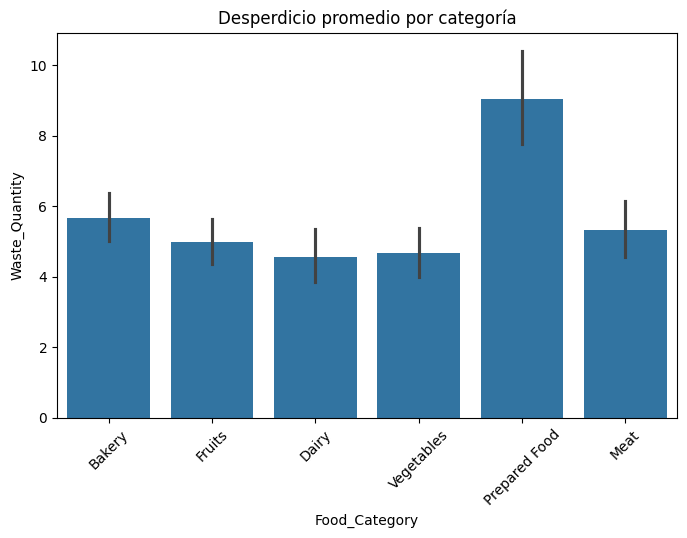

Se observa que la categoría de Pepared Food (comida preparada) tiene el mayor desperdicio promedio mientras que Dairy (lácteos) tiene el menor desperdicio.


In [18]:
# comparamos el desperdicio promedio por categoría de alimento utilizando un gráfico de barras

plt.figure(figsize=(8,5))

sns.barplot(data=raw_df,x='Food_Category',y='Waste_Quantity',estimator=np.mean)

plt.title('Desperdicio promedio por categoría')

plt.xticks(rotation=45)

plt.show()

print("Se observa que la categoría de Pepared Food (comida preparada) tiene el mayor desperdicio promedio mientras que Dairy (lácteos) tiene el menor desperdicio.")

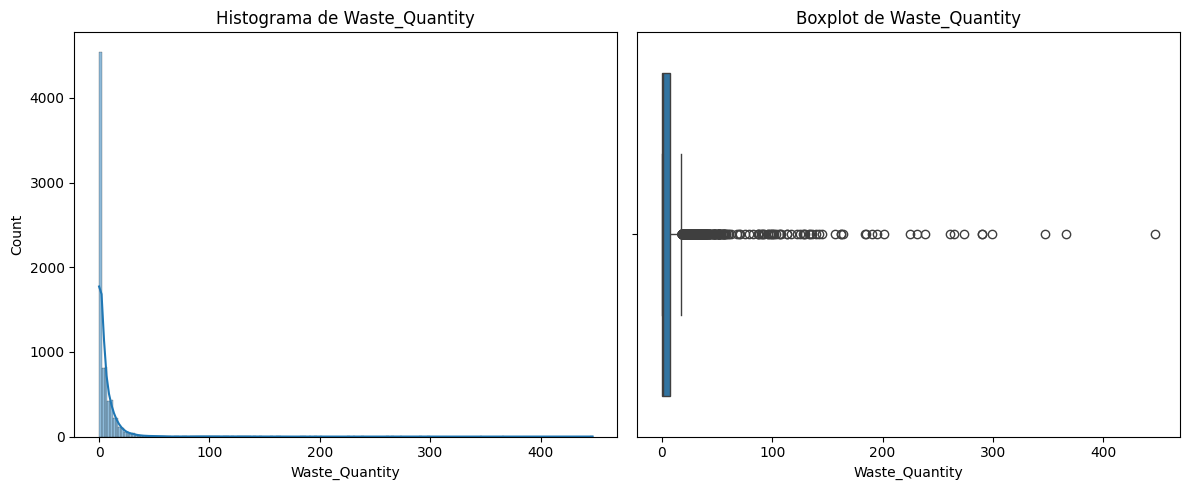

La mayor parte de los registros presenta cantidades bajas de desperdicio de alimentos. Sin embargo, existen varios valores atípicos elevados, 
 lo que provoca que la distribución de Waste_Quantity esté sesgada hacia la derecha.
 Aunque existen valores extremos elevados, estos podrían representar situaciones reales de desperdicio y no necesariamente errores de registro


In [19]:
fig, ax = plt.subplots(1, 2, figsize=(12,5))

# Histograma
sns.histplot(raw_df['Waste_Quantity'],kde=True,ax=ax[0])

ax[0].set_title('Histograma de Waste_Quantity')

# Boxplot
sns.boxplot(x=raw_df['Waste_Quantity'],ax=ax[1])

ax[1].set_title('Boxplot de Waste_Quantity')

plt.tight_layout()
plt.show()

print("La mayor parte de los registros presenta cantidades bajas de desperdicio de alimentos. Sin embargo, existen varios valores atípicos elevados," \
" \n lo que provoca que la distribución de Waste_Quantity esté sesgada hacia la derecha.\n Aunque existen valores extremos elevados, estos podrían representar situaciones reales de desperdicio y no necesariamente errores de registro")

In [20]:
print ("Análisis de los outliers en la variable Waste_Quantity.")

Q1 = raw_df['Waste_Quantity'].quantile(0.25)

Q3 = raw_df['Waste_Quantity'].quantile(0.75)

IQR = Q3 - Q1 #rango intercuartílico

limite_superior = Q3 + 1.5 * IQR # Límite superior utilizado para detectar outliers.

outliers = (raw_df['Waste_Quantity'] > limite_superior).sum() # le pedimos cuente cuántos registros superan el límite superior, es decir, cuántos outliers hay en la variable Waste_Quantity.

print("Límite superior:", limite_superior, "\n") # Mostramos el valor a partir del cual un registro será considerado un outlier.

print("Cantidad de outliers:", outliers, "\n") # Mostramamos la cantidad de registros considerados outliers en la variable Waste_Quantity.

print ("Observamos q son 550 registros los cuales no se eliminaran porq pueden ser valores reales de desperdicio y no necesariamente errores de registro.\nPor lo tanto, se decide mantenerlos en el conjunto de datos para el entrenamiento del modelo.\n")

outliers_df = raw_df[raw_df['Waste_Quantity'] > limite_superior]

print(outliers_df['Business_Type'].value_counts())

outliers_df.groupby('Business_Type')['Waste_Quantity'].describe()

print ("Vemos cuantos nulos hay en las columnas numericas\n")

num_cols = raw_df.select_dtypes(include=['int64', 'float64']).columns

print(raw_df[num_cols].isnull().sum(),"\n")

print("Vemos cuantos nulos hay en las columnas categoricas")

cat_cols = raw_df.select_dtypes(include=['object']).columns

print(raw_df[cat_cols].isnull().sum())



Análisis de los outliers en la variable Waste_Quantity.
Límite superior: 17.5 

Cantidad de outliers: 550 

Observamos q son 550 registros los cuales no se eliminaran porq pueden ser valores reales de desperdicio y no necesariamente errores de registro.
Por lo tanto, se decide mantenerlos en el conjunto de datos para el entrenamiento del modelo.

Business_Type
Supermarket      330
Restaurant       104
Cloud Kitchen     86
Cafeteria         30
Name: count, dtype: int64
Vemos cuantos nulos hay en las columnas numericas

Purchase_Quantity        0
Shelf_Life_Days        235
Storage_Temperature    186
Daily_Demand           210
Waste_Quantity           0
dtype: int64 

Vemos cuantos nulos hay en las columnas categoricas
Business_Type      0
Food_Category      0
Promotion          0
Weather          203
dtype: int64


Analizamos la correlación entre las variables numéricas utilizando un mapa de calor


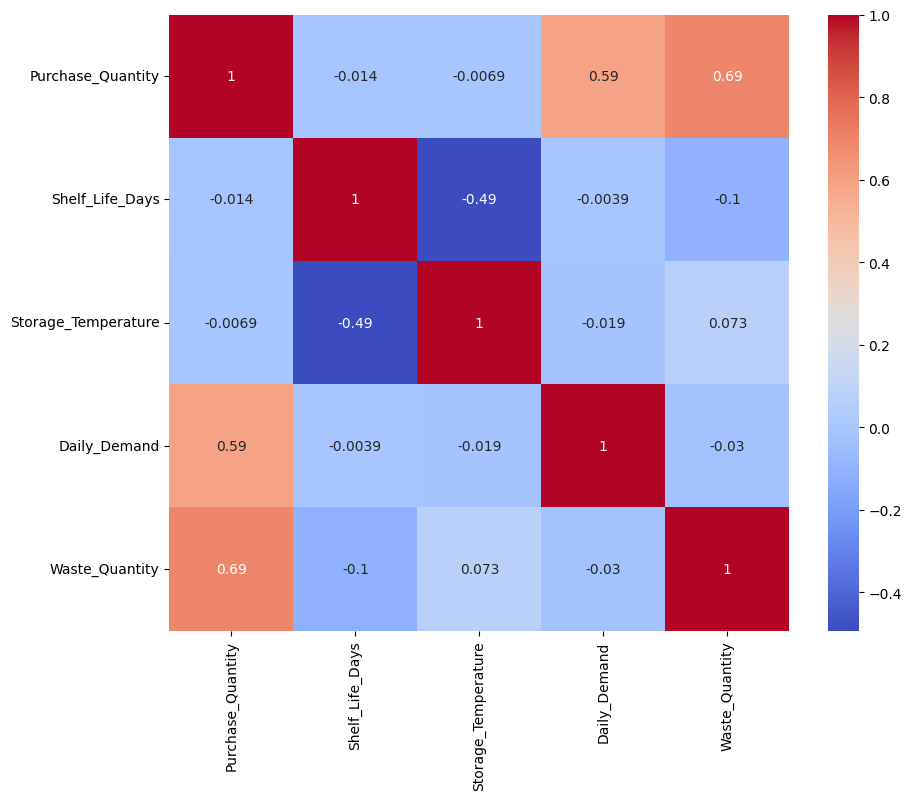

El stock restante muestra la mayor correlación con el desperdicio.Sin embargo,
posteriormente se elimina del modelado para evitar incorporar información demasiado cercana a la variable objetivo.


In [21]:
print("Analizamos la correlación entre las variables numéricas utilizando un mapa de calor") 

plt.figure(figsize=(10,8))

sns.heatmap(raw_df.select_dtypes(include=[np.number]).corr(), annot=True, cmap='coolwarm')

plt.show()

print("El stock restante muestra la mayor correlación con el desperdicio.Sin embargo,\nposteriormente se elimina del modelado para evitar incorporar información demasiado cercana a la variable objetivo.")

  ### **Preparación de los datos para el modelado:**

In [22]:
print("Se crea una nueva variable binaria que indica si hubo desperdicio de alimentos o no. Esta variable será utilizada como objetivo en el modelo de regresión logística.")

raw_df['Hubo_Desperdicio'] = (raw_df['Waste_Quantity'] > 0).astype(int)

print("Analizamos la distribución de las clases de la variable Hubo_Desperdicio para evaluar el balance del conjunto de datos.\n")
print ("Se puede observar que los datos estan bastantes balanceados, esta variable sera usada luego para la regresion logistica")

raw_df['Hubo_Desperdicio'].value_counts(normalize=True).map('{:.2%}'.format)

Se crea una nueva variable binaria que indica si hubo desperdicio de alimentos o no. Esta variable será utilizada como objetivo en el modelo de regresión logística.
Analizamos la distribución de las clases de la variable Hubo_Desperdicio para evaluar el balance del conjunto de datos.

Se puede observar que los datos estan bastantes balanceados, esta variable sera usada luego para la regresion logistica


Hubo_Desperdicio
1    57.31%
0    42.69%
Name: proportion, dtype: object

In [23]:
print ("El conjunto de datos fue ordenado cronológicamente y dividido temporalmente en entrenamiento (58,68%), validación (16,41%) y prueba (24,91%).\n")

raw_df = raw_df.sort_values("Date")

train_df = raw_df[(raw_df["Date"] < "2025-08-01")]

validation_df = raw_df[(raw_df["Date"] >= "2025-08-01") & (raw_df["Date"] < "2025-10-01")]

test_df = raw_df[(raw_df["Date"] >= "2025-10-01")]

total = len(raw_df)
print(f"Entrenamiento: {len(train_df)} registros ({len(train_df)/total*100:.2f}%)")
print(f"Validación: {len(validation_df)} registros ({len(validation_df)/total*100:.2f}%)")
print(f"Prueba: {len(test_df)} registros ({len(test_df)/total*100:.2f}%)")

El conjunto de datos fue ordenado cronológicamente y dividido temporalmente en entrenamiento (58,68%), validación (16,41%) y prueba (24,91%).

Entrenamiento: 4694 registros (58.67%)
Validación: 1313 registros (16.41%)
Prueba: 1993 registros (24.91%)


In [24]:
print("  Se separan las variables predictoras y la variable objetivo en los conjuntos de entrenamiento, validación y prueba.\n " \
      " Se excluyen Waste_Quantity, Date y Hubo_Desperdicio de las variablespredictoras, ya que Waste_Quantity corresponde a la variable objetivo del modelo de regresión,\n"\
      "  Date se utiliza únicamente para la división temporaldel conjunto de datos y Hubo_Desperdicio será utilizada posteriormente como variable objetivo en el modelo de clasificación.")

target = "Waste_Quantity"  # Variable objetivo que se desea predecir.

# Variables predictoras y objetivo del conjunto de entrenamiento.
X_train = train_df.drop(columns=[target, "Date", "Hubo_Desperdicio"])
y_train = train_df[target]

# Variables predictoras y objetivo del conjunto de validación.
X_val = validation_df.drop(columns=[target, "Date", "Hubo_Desperdicio"])
y_val = validation_df[target]

# Variables predictoras y objetivo del conjunto de prueba.
X_test = test_df.drop(columns=[target, "Date", "Hubo_Desperdicio"])
y_test = test_df[target]


  Se separan las variables predictoras y la variable objetivo en los conjuntos de entrenamiento, validación y prueba.
  Se excluyen Waste_Quantity, Date y Hubo_Desperdicio de las variablespredictoras, ya que Waste_Quantity corresponde a la variable objetivo del modelo de regresión,
  Date se utiliza únicamente para la división temporaldel conjunto de datos y Hubo_Desperdicio será utilizada posteriormente como variable objetivo en el modelo de clasificación.


In [25]:
print("Identificamos las variables numéricas y categóricas a partir del conjunto de entrenamiento para aplicar el preprocesamiento correspondiente.\n")

columnas_numericas = X_train.select_dtypes(include=np.number).columns

print ("Columnas numericas:\n", columnas_numericas)

columnas_categoricas = X_train.select_dtypes(exclude=np.number).columns

print ("columnas categoricas\n", columnas_categoricas)

Identificamos las variables numéricas y categóricas a partir del conjunto de entrenamiento para aplicar el preprocesamiento correspondiente.

Columnas numericas:
 Index(['Purchase_Quantity', 'Shelf_Life_Days', 'Storage_Temperature',
       'Daily_Demand'],
      dtype='object')
columnas categoricas
 Index(['Business_Type', 'Food_Category', 'Promotion', 'Weather'], dtype='object')


In [26]:
print(" Se define un Pipeline para las variables numéricas, reemplazando los valores faltantes mediante la mediana calculada sobre el conjunto de entrenamiento\n " \
"y escalando las variables para llevarlas a una misma escala.")
pipeline_num = Pipeline([
    ('imputer', SimpleImputer(strategy='median')), # completa los nulos con la mediana calculada únicamente con el conjunto de entrenamiento.
    ('scaler', StandardScaler()) # Escala las variables para llevarlas a una misma escala.
])

 Se define un Pipeline para las variables numéricas, reemplazando los valores faltantes mediante la mediana calculada sobre el conjunto de entrenamiento
 y escalando las variables para llevarlas a una misma escala.


In [27]:
print("Se define un Pipeline para las variables categóricas, reemplazando los valores faltantes con la categoría más frecuente y transformándolas mediante One-Hot Encoding.")

pipeline_cat = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')), # Reemplaza los valores faltantes con la categoría más frecuente calculada únicamente sobre el conjunto de entrenamiento.
    ('onehot', OneHotEncoder(drop='first')) # Convierte las variables categóricas en variables numéricas mediante One-Hot Encoding.
])

Se define un Pipeline para las variables categóricas, reemplazando los valores faltantes con la categoría más frecuente y transformándolas mediante One-Hot Encoding.


In [28]:
print("Se define un preprocesador que aplica automáticamente el tratamiento correspondiente a las variables numéricas y categóricas.")

preprocesador = ColumnTransformer([
    ('num', pipeline_num, columnas_numericas),
    ('cat', pipeline_cat, columnas_categoricas)
])

Se define un preprocesador que aplica automáticamente el tratamiento correspondiente a las variables numéricas y categóricas.


  ### **Modelos de Regresion:**

In [29]:
print("Se crean los modelos de Regresión Lineal y Random Forest utilizando el preprocesador definido anteriormente.")

modelo_lineal = Pipeline([
    ('prep', preprocesador),
    ('reg', LinearRegression())
])


modelo_random = Pipeline([
    ('prep', preprocesador),
    ('reg', RandomForestRegressor(random_state=42))
])



Se crean los modelos de Regresión Lineal y Random Forest utilizando el preprocesador definido anteriormente.


In [30]:
print("Se entrenan ambos modelos utilizando el conjunto de entrenamiento.")

modelo_lineal.fit(X_train, y_train)

modelo_random.fit(X_train, y_train)

Se entrenan ambos modelos utilizando el conjunto de entrenamiento.


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('reg', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains spa

In [31]:
print("Se realizan predicciones sobre el conjunto de validación para evaluar y comparar ambos modelos.")

pred_lineal = modelo_lineal.predict(X_val)

pred_random = modelo_random.predict(X_val)

Se realizan predicciones sobre el conjunto de validación para evaluar y comparar ambos modelos.


In [32]:
print("Se comparan las métricas obtenidas por ambos modelos sobre el conjunto de validación para seleccionar la mejor alternativa.")

rmse_lineal = np.sqrt(mean_squared_error(y_val, pred_lineal))
mae_lineal = mean_absolute_error(y_val, pred_lineal)
r2_lineal = r2_score(y_val, pred_lineal)
print("=== Regresión Lineal ===")
print("RMSE:", round(rmse_lineal, 2))
print("MAE:", round(mae_lineal, 2))
print("R²:", round(r2_lineal, 2))


rmse_random = np.sqrt(mean_squared_error(y_val, pred_random))
mae_random = mean_absolute_error(y_val, pred_random)
r2_random = r2_score(y_val, pred_random)
print("\n=== Random Forest ===")
print("RMSE:", round(rmse_random, 2))
print("MAE:", round(mae_random, 2))
print("R²:", round(r2_random, 2))

Se comparan las métricas obtenidas por ambos modelos sobre el conjunto de validación para seleccionar la mejor alternativa.
=== Regresión Lineal ===
RMSE: 6.15
MAE: 4.2
R²: 0.86

=== Random Forest ===
RMSE: 3.5
MAE: 1.29
R²: 0.96


In [33]:
print("Se comparan las métricas de entrenamiento para detectar posibles signos de sobreajuste.")

pred_train_lineal = modelo_lineal.predict(X_train)

pred_train_random = modelo_random.predict(X_train)

print("R² train lineal:",
      round(r2_score(y_train, pred_train_lineal), 3))

print("R² train random:",
      round(r2_score(y_train, pred_train_random), 3))

Se comparan las métricas de entrenamiento para detectar posibles signos de sobreajuste.
R² train lineal: 0.8
R² train random: 0.985


In [34]:
print("Se analiza si los modelos generan predicciones negativas, ya que una cantidad de desperdicio menor a cero no tiene interpretación válida en un contexto real.\n")

print("Negativos Validación Lineal:",
      (pred_lineal < 0).sum())

print("Negativos Validación Random:",
      (pred_random < 0).sum())

print("Negativos Entrenamiento Lineal:",
      (pred_train_lineal < 0).sum())

print("Negativos Entrenamiento Random:",
      (pred_train_random < 0).sum())

Se analiza si los modelos generan predicciones negativas, ya que una cantidad de desperdicio menor a cero no tiene interpretación válida en un contexto real.

Negativos Validación Lineal: 393
Negativos Validación Random: 0
Negativos Entrenamiento Lineal: 1400
Negativos Entrenamiento Random: 0


##### Random Forest fue seleccionado como modelo final por presentar el mejor desempeño en validación, no generar predicciones negativas y mostrar resultados consistentes entre entrenamiento y validación


  ### **Evaluación del modelo final sobre el conjunto de prueba:**

In [35]:

pred_test_random = modelo_random.predict(X_test)

In [36]:
print("Verificamos que el modelo final no genere predicciones negativas sobre el conjunto de prueba.\n")

print("Negativos Test Random:",
      (pred_test_random < 0).sum())

Verificamos que el modelo final no genere predicciones negativas sobre el conjunto de prueba.

Negativos Test Random: 0


In [37]:
print("Se evalúa el desempeño del modelo final sobre el conjunto de prueba utilizando las métricas RMSE, MAE y R².")

rmse_test = np.sqrt(mean_squared_error(y_test, pred_test_random))
mae_test = mean_absolute_error(y_test, pred_test_random)
r2_test = r2_score(y_test, pred_test_random)

print("RMSE Test:", round(rmse_test, 2))
print("MAE Test:", round(mae_test, 2))
print("R² Test:", round(r2_test, 2))

print("Los resultados obtenidos sobre el conjunto de prueba permiten estimar el desempeño del modelo frente a datos no utilizados durante el entrenamiento ni la validación.")

Se evalúa el desempeño del modelo final sobre el conjunto de prueba utilizando las métricas RMSE, MAE y R².
RMSE Test: 5.96
MAE Test: 1.51
R² Test: 0.88
Los resultados obtenidos sobre el conjunto de prueba permiten estimar el desempeño del modelo frente a datos no utilizados durante el entrenamiento ni la validación.


  ### **Modelo de Clasificacion:**

In [38]:
print("Se preparan los datos para el modelo de regresión logística.")

target = "Hubo_Desperdicio"

# Entrenamiento
X_train_log = train_df.drop(
    columns=[target, "Waste_Quantity", "Date"]
)
y_train_log = train_df[target]

# Validación
X_val_log = validation_df.drop(
    columns=[target, "Waste_Quantity", "Date"]
)
y_val_log = validation_df[target]

# Prueba
X_test_log = test_df.drop(
    columns=[target, "Waste_Quantity", "Date"]
)
y_test_log = test_df[target]

Se preparan los datos para el modelo de regresión logística.


In [39]:
print("Se crea el modelo de regresión logística para predecir si habrá o no desperdicio de alimentos.\n")

modelo_logistico = Pipeline([
    ('prep', preprocesador),
    ('clf', LogisticRegression(max_iter=1000))
])

Se crea el modelo de regresión logística para predecir si habrá o no desperdicio de alimentos.



In [40]:
print("Se entrena el modelo de regresión logística utilizando el conjunto de entrenamiento.")

modelo_logistico.fit(
    X_train_log,
    y_train_log
)

Se entrena el modelo de regresión logística utilizando el conjunto de entrenamiento.


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains spa

In [41]:
print("Se generan predicciones sobre el conjunto de validación para evaluar el desempeño del modelo de clasificación.")

pred_logistico = modelo_logistico.predict(X_val_log)

Se generan predicciones sobre el conjunto de validación para evaluar el desempeño del modelo de clasificación.


In [42]:
print("Se calculan las probabilidades estimadas de que ocurra desperdicio para evaluar el modelo mediante la métrica ROC AUC.")

y_proba = modelo_logistico.predict_proba(X_val_log)[:,1]

Se calculan las probabilidades estimadas de que ocurra desperdicio para evaluar el modelo mediante la métrica ROC AUC.


In [43]:
print("Se evalúa el modelo de clasificación utilizando Accuracy, F1 Score y ROC AUC.")

print("Accuracy:", round(accuracy_score(y_val_log, pred_logistico),3))

print("F1 Score:", round(f1_score(y_val_log, pred_logistico),3))

print("ROC AUC:", round(roc_auc_score(y_val_log, y_proba),3))

Se evalúa el modelo de clasificación utilizando Accuracy, F1 Score y ROC AUC.
Accuracy: 0.952
F1 Score: 0.958
ROC AUC: 0.984


Se analiza el desempeño del modelo mediante una matriz de confusión, identificando los casos correctamente e incorrectamente clasificados.


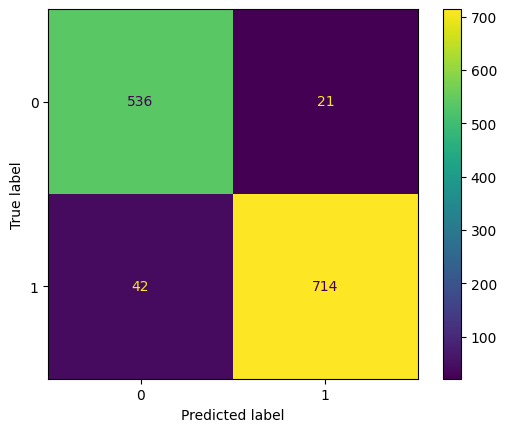

La matriz de confusión evidencia un buen desempeño del modelo, con 1.250 clasificaciones correctas y un número reducido de errores
Esto indica que la regresión logística es capaz de distinguir adecuadamente entre registros con y sin desperdicio de alimentos.


In [44]:
print("Se analiza el desempeño del modelo mediante una matriz de confusión, identificando los casos correctamente e incorrectamente clasificados.")

ConfusionMatrixDisplay.from_predictions(
    y_val_log,
    pred_logistico
)

plt.show()

print("La matriz de confusión evidencia un buen desempeño del modelo, con 1.250 clasificaciones correctas y un número reducido de errores\n" \
"Esto indica que la regresión logística es capaz de distinguir adecuadamente entre registros con y sin desperdicio de alimentos.")


In [45]:
aciertos = (y_val_log == pred_logistico).sum()

porcentaje_aciertos = (aciertos / len(y_val_log)) * 100

print(f"Cantidad de aciertos: {aciertos} registros equivalentes al {porcentaje_aciertos:.2f}% del conjunto de validación")


Cantidad de aciertos: 1250 registros equivalentes al 95.20% del conjunto de validación


Evaluamos la capacidad del modelo para distinguir entre registros con y sin desperdicio.


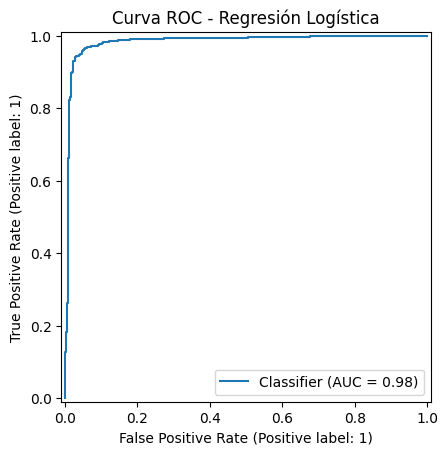

La curva ROC y el valor de ROC AUC evidencian una excelente capacidad del modelo para distinguir entre ambas clases.


In [46]:
print("Evaluamos la capacidad del modelo para distinguir entre registros con y sin desperdicio.")

RocCurveDisplay.from_predictions(
    y_val_log,
    y_proba
)

plt.title("Curva ROC - Regresión Logística")
plt.show()

print("La curva ROC y el valor de ROC AUC evidencian una excelente capacidad del modelo para distinguir entre ambas clases.")

  ### **Resumen de validación:**

In [47]:
resumen_validacion = pd.DataFrame({
    'Modelo': ['Regresión Lineal', 'Random Forest', 'Regresión Logística'],
    'RMSE': [round(rmse_lineal, 2), round(rmse_random, 2), '-'],
    'MAE': [round(mae_lineal, 2), round(mae_random, 2), '-'],
    'R²': [f"{r2_lineal*100:.2f}%", f"{r2_random*100:.2f}%", '-'],
    'Accuracy': ['-', '-', f"{accuracy_score(y_val_log, pred_logistico)*100:.2f}%"],
    'F1 Score': ['-', '-', f"{f1_score(y_val_log, pred_logistico)*100:.2f}%"],
    'ROC AUC': ['-', '-', round(roc_auc_score(y_val_log, y_proba), 3)]
})

display(resumen_validacion)

,Modelo,RMSE,MAE,R²,Accuracy,F1 Score,ROC AUC
0,Regresión Lineal,6.15,4.2,86.36%,-,-,-
1,Random Forest,3.5,1.29,95.57%,-,-,-
2,Regresión Logística,-,-,-,95.20%,95.77%,0.984


La selección de modelos se realizó utilizando exclusivamente el conjunto de validación. Los modelos de regresión fueron evaluados mediante RMSE,MAE y R², mientras que la Regresión Logística se evaluó mediante Accuracy, F1-Score y ROC AUC."

Conclusión: Random Forest fue seleccionado como modelo principal de regresión debido a su mejor desempeño en validación, la ausencia de predicciones negativas y su adecuada capacidad de generalización.


  ### **Interpretación de las variables del modelo Random Forest:**

Se analizó la importancia de las variables del modelo Random Forest para identificar cuáles son los factores que más influyen en la predicción del desperdicio de alimentos.

In [48]:
print("Se analiza la importancia de las variables del modelo para comprender qué factores contribuyen en mayor medida a la predicción del desperdicio.\n")

columnas_modelo = preprocesador.get_feature_names_out()

importancias = modelo_random.named_steps['reg'].feature_importances_

df_importancia = pd.DataFrame({
    'Variable': columnas_modelo,
    'Importancia (%)': (importancias * 100).round(2)
})

df_importancia = df_importancia.sort_values(
    'Importancia (%)',
    ascending=False
)

display(df_importancia)

Se analiza la importancia de las variables del modelo para comprender qué factores contribuyen en mayor medida a la predicción del desperdicio.



,Variable,Importancia (%)
0,num__Purchase_Quantity,79.75
3,num__Daily_Demand,9.43
2,num__Storage_Temperature,4.41
14,cat__Weather_Rainy,2.68
1,num__Shelf_Life_Days,1.84
6,cat__Business_Type_Supermarket,0.33
10,cat__Food_Category_Prepared Food,0.33
13,cat__Weather_Hot,0.24
11,cat__Food_Category_Vegetables,0.20
12,cat__Promotion_Yes,0.19


La variable Purchase_Quantity representa aproximadamente el 79,75% de la importancia total del modelo, siendo por amplio margen el factor más influyente en la predicción del desperdicio. Esto sugiere que comprar más productos de los que finalmente se demandan constituye una de las principales causas asociadas al desperdicio de alimentos.

La variable Daily_Demand tiene una importancia cercana al 9,43%, indicando que la estimación de la demanda también cumple un rol relevante. Una planificación incorrecta de las ventas esperadas puede generar excedentes de inventario que terminan siendo descartados.

Storage_Temperature aporta aproximadamente el 4,41% de la importancia del modelo. Esto demuestra que las condiciones de almacenamiento influyen en la conservación de los productos y, en consecuencia, en la cantidad de desperdicio generada.

Entre las variables categóricas, Weather_Rainy presenta la mayor importancia relativa. Esto podría indicar que determinadas condiciones climáticas modifican los patrones de consumo y afectan indirectamente la cantidad de alimentos desperdiciados.

En conjunto, los resultados sugieren que la gestión de compras, la estimación de la demanda y las condiciones de almacenamiento son los principales factores asociados al desperdicio alimentario en este conjunto de datos.

  ### **Impacto económico potencial:**


In [49]:
print("Se plantea un escenario hipotético donde cada unidad desperdiciada representa una pérdida de $10.\n")

costo_por_unidad = 10

reduccion_desperdicio = 100

ahorro_potencial = costo_por_unidad * reduccion_desperdicio

print(f"Si el negocio lograra reducir el desperdicio en {reduccion_desperdicio} unidades, el ahorro potencial sería de aproximadamente ${ahorro_potencial:.2f}.\n")

print("Dado que Purchase_Quantity y Daily_Demand fueron las variables más importantes del modelo, una mejor planificación \n\
de compras e inventario podría contribuir a reducir el desperdicio y generar ahorros económicos.")

Se plantea un escenario hipotético donde cada unidad desperdiciada representa una pérdida de $10.

Si el negocio lograra reducir el desperdicio en 100 unidades, el ahorro potencial sería de aproximadamente $1000.00.

Dado que Purchase_Quantity y Daily_Demand fueron las variables más importantes del modelo, una mejor planificación 
de compras e inventario podría contribuir a reducir el desperdicio y generar ahorros económicos.


 ### **Segmentación del desempeño del modelo:**

In [56]:
print("Se analiza el error promedio del modelo según el tipo de negocio para evaluar si su desempeño es consistente en los distintos segmentos.")


resultados_random = X_test.copy()

resultados_random["Business_Type"] = test_df["Business_Type"]
resultados_random["Real"] = y_test
resultados_random["Prediccion"] = pred_test_random

resultados_random["Error"] = abs(
    resultados_random["Real"] -
    resultados_random["Prediccion"]
)

display(resultados_random.groupby("Business_Type")["Error"].mean().sort_values())

print("El modelo presentó un desempeño diferente según el tipo de negocio. Las Cafeterias registraron el menor error promedio, mientras que los\n\
supermercados mostraron el mayor error, lo que sugiere que la dificultad de predicción varía entre los distintos segmentos analizados.")

Se analiza el error promedio del modelo según el tipo de negocio para evaluar si su desempeño es consistente en los distintos segmentos.


Business_Type
Cafeteria        0.681011
Restaurant       1.057337
Cloud Kitchen    1.434358
Supermarket      2.510758
Name: Error, dtype: float64

El modelo presentó un desempeño diferente según el tipo de negocio. Las Cafeterias registraron el menor error promedio, mientras que los
supermercados mostraron el mayor error, lo que sugiere que la dificultad de predicción varía entre los distintos segmentos analizados.


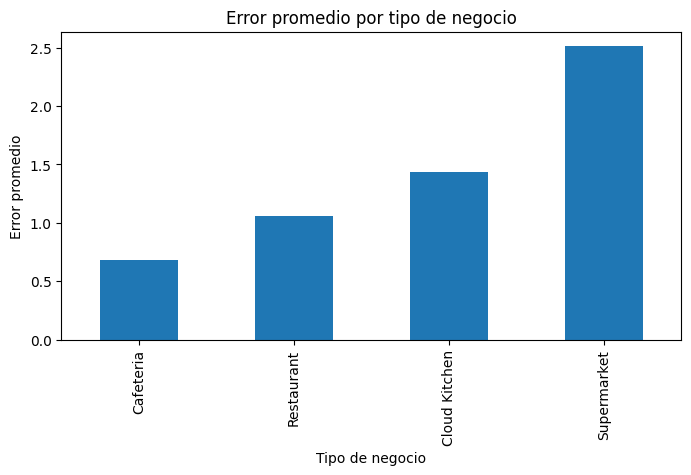

In [51]:
mae_por_negocio = (
    resultados_random.groupby("Business_Type")["Error"]
    .mean()
    .sort_values()
)

plt.figure(figsize=(8,4))
mae_por_negocio.plot(kind="bar")

plt.title("Error promedio por tipo de negocio")
plt.xlabel("Tipo de negocio")
plt.ylabel("Error promedio")

plt.show()